# 1. Application outcome funnel

Where do past applications end up, and for whom? Source: `previous_application` (approved / refused / canceled / unused offer). **This is outcome data, not a click-by-click UX funnel.**

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

METRICS = json.loads((ROOT / "reports" / "metrics.json").read_text())
SOURCE = METRICS["meta"]["data_source"]
display(Markdown(
    "> **Data source: real Home Credit data.**" if METRICS["meta"]["resume_safe"]
    else "> ⚠️ **SYNTHETIC DATA. Plumbing check only; do not read these numbers as findings.**"))

def load_application():
    """Real CSV if present and the reports came from it, otherwise the synthetic stand-in."""
    from src import synthetic
    path = ROOT / "data" / "application_train.csv"
    if METRICS["meta"]["resume_safe"] and path.exists():
        from src.pipeline import APP_COLUMNS
        return pd.read_csv(path, usecols=APP_COLUMNS)
    return synthetic.make_application_train(n=METRICS["meta"]["n_rows"], seed=METRICS["meta"]["seed"])


> **Data source: real Home Credit data.**

In [2]:
import duckdb
from src.funnel import SEGMENT_SQL, run_funnel
path = ROOT / "data" / "previous_application.csv"
if METRICS["meta"]["resume_safe"] and path.exists():
    source = path
else:
    from src import synthetic; source = synthetic.make_previous_application()
result = run_funnel(source)
con = duckdb.connect()
con.register("prev", source) if isinstance(source, pd.DataFrame) else con.execute(f"CREATE VIEW prev AS SELECT * FROM read_csv_auto('{source}')")
print("Total applications:", f"{result['summary']['total_rows']:,}")

Total applications: 1,670,214


## Overall outcomes (SQL)

In [3]:
con.execute("""
SELECT NAME_CONTRACT_STATUS AS status, COUNT(*) AS n,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM prev GROUP BY 1 ORDER BY n DESC""").df()

,status,n,pct
0,Approved,1036781,62.1
1,Canceled,316319,18.9
2,Refused,290678,17.4
3,Unused offer,26436,1.6


## Refusal rate by segment (SQL)

In [4]:
seg = result["segments"]
for dim in ["NAME_CLIENT_TYPE", "NAME_CONTRACT_TYPE", "NAME_PORTFOLIO"]:
    display(Markdown(f"**{dim}**"))
    display(seg[(seg.dimension == dim) & (seg.n >= 0.01 * result["summary"]["total_rows"])].drop(columns="dimension"))

**NAME_CLIENT_TYPE**

,segment,n,approved_pct,refused_pct,canceled_pct,unused_pct
4,Repeater,1231261,53.4,21.2,23.7,1.7
5,New,301363,93.3,4.8,1.2,0.7
6,Refreshed,135649,71.6,11.1,14.4,2.9


**NAME_CONTRACT_TYPE**

,segment,n,approved_pct,refused_pct,canceled_pct,unused_pct
0,Cash loans,747553,41.8,22.2,35.9,0.1
1,Consumer loans,729151,85.9,10.3,0.2,3.6
2,Revolving loans,193164,50.6,25.6,23.7,0.0


**NAME_PORTFOLIO**

,segment,n,approved_pct,refused_pct,canceled_pct,unused_pct
17,POS,691011,90.6,9.2,0.0,0.1
18,Cash,461563,67.7,30.2,2.1,0.0
19,XNA,372230,0.0,11.0,82.2,6.9
20,Cards,144985,67.4,32.2,0.3,0.0


## Does the hour or weekday matter?

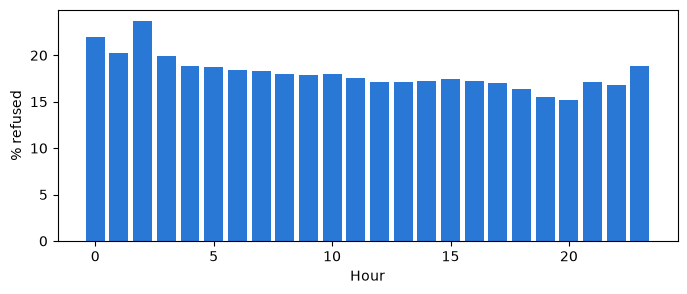

,segment,n,approved_pct,refused_pct,canceled_pct,unused_pct
22,TUESDAY,255118,59.3,18.3,21.1,1.4
23,WEDNESDAY,255010,59.6,18.2,20.8,1.4
24,MONDAY,253557,59.0,18.2,21.3,1.5
25,FRIDAY,252048,60.7,18.1,19.7,1.5
26,THURSDAY,249099,60.0,18.2,20.4,1.4
27,SATURDAY,240631,67.7,15.6,14.9,1.8
28,SUNDAY,164751,71.8,14.1,11.7,2.4


In [5]:
hour = seg[seg.dimension == "HOUR_APPR_PROCESS_START"].assign(h=lambda d: d.segment.astype(int)).sort_values("h")
fig, ax = plt.subplots(figsize=(8, 3)); ax.bar(hour.h, hour.refused_pct, color="#2a78d6"); ax.set_xlabel("Hour"); ax.set_ylabel("% refused"); plt.show()
seg[seg.dimension == "WEEKDAY_APPR_PROCESS_START"].drop(columns="dimension")

## Findings (computed, not typed)

In [6]:
for line in result["summary"]["findings"]:
    print("•", line)
print(f"• {result['summary']['unused_share_of_offers_pct']}% of offers made (approved + unused) were never used.")

• By client type, refusal rate ranges from 4.8% (New, n=301,363) to 21.2% (Repeater, n=1,231,261).
• By contract type, refusal rate ranges from 10.3% (Consumer loans, n=729,151) to 25.6% (Revolving loans, n=193,164).
• 2.5% of offers made (approved + unused) were never used.


**Reading this honestly:** a high refusal rate for new clients says new clients are refused more often, not why. Reject reasons (`CODE_REJECT_REASON`) hint at the policy lever; proving causality would need an experiment.